In [5]:
# import mediapipe as mp
# from mediapipe.tasks import python
# from mediapipe.tasks.python import vision
# from mediapipe import solutions
import numpy as np
import cv2
import pandas as pd
import math
import os
import json
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
cwd = os.getcwd()
base_data_path = os.path.join(cwd, "asl citizen data", "ASL_Citizen")
videos_path = os.path.join(base_data_path, "videos")
splits_path = os.path.join(base_data_path, "splits")

In [3]:
train = pd.read_csv(os.path.join(splits_path, "train.csv"))
test = pd.read_csv(os.path.join(splits_path, "test.csv"))
val = pd.read_csv(os.path.join(splits_path, "val.csv"))

In [4]:
train.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
test.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
val.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
train.head()

,participant,path,gloss,code
0,P1,15890366051589533-APPLE.mp4,APPLE,A_03_054
1,P1,35618482303951104-IMPOSSIBLE.mp4,IMPOSSIBLE,B_01_032
2,P1,6958143575951994-PARK.mp4,PARK,E_03_028
3,P1,8006032738002744-SOCCER 2.mp4,SOCCER2,F_03_032
4,P1,37542279833186454-STINK.mp4,STINK,H_01_064


In [ ]:
train.groupby("gloss").count().sort_values(by="path")

participant    14.703039
path           14.703039
code           14.670817
dtype: float64

In [18]:
train[train['gloss'] == "HELLO"].groupby("gloss").count()

,participant,path,code
gloss,,,
HELLO,14,14,14


## Deprecated generator

The inline generator previously stored absolute landmark positions in relative-motion history and passed BGR frames to MediaPipe as RGB. It has been retired. Use the shared `DataGeneration` workflow in the next cell.


In [6]:
target_words = [
    "HELLO",
    "GOOD",
    "BAD",
    "YES",
    "NO",
    "PLEASE",
    "THANKYOU",
    "SORRY",
    "HELP",
    "ME",
    "YOU",
    "WE",
    "THEY1",
    "MY",
    "YOUR",
    "WHAT1",
    "WHERE",
    "WHEN",
    "WHY",
    "WHO",
    "HOW1",
    "WANT1",
    "NEED",
    "LIKE",
    "LOVE",
    "KNOW",
    "DONTKNOW",
    "UNDERSTAND",
    "GO",
    "COME",
    "STOP",
    "WAIT",
    "GIVE",
    "TAKE",
    "EAT1",
    "DRINK1",
    "SLEEP",
    "HOME",
    "SCHOOL",
    "WORK",
    "FRIEND",
    "FAMILY",
    "MOTHER",
    "FATHER",
    "NOW",
    "TODAY",
    "TOMORROW",
    "BATHROOM",
    "WATER",
    "FINISH",
    "MORE",
    "ORANGEEYES"
]

In [7]:
# Generate corrected raw landmark data for every split.
# This is expensive and only needs to run when rebuilding the dataset.
from data_generation import DataGeneration

data_gen = DataGeneration(videos_path)
data_gen.set_target_words(target_words)

worker_count = 10

if __name__ == "__main__":
    print("Gathering training data...")
    data_gen.generate_from_dataset(train, "train", True, max_workers=worker_count, limit_count=False, use_target_words_only=False)
    print("Gathering testing data...")
    data_gen.generate_from_dataset(test, "test", True, max_workers=worker_count, limit_count=False, use_target_words_only=False)
    print("Gathering validation data...")
    data_gen.generate_from_dataset(val, "val", True, max_workers=worker_count, limit_count=False, use_target_words_only=False)


Gathering training data...


NameError: name 'train' is not defined

In [ ]:
# # DATA CLEANING. SHOULD ONLY BE RUN WHEN GENERATING NEW DATA

import os
import h5py
import numpy as np
import pandas as pd


raw_gesture_data_folder = os.path.join(cwd, "asl_citizen_gesture_data/raw_data")

raw_test = os.path.join(raw_gesture_data_folder, "test")
raw_train = os.path.join(raw_gesture_data_folder, "train")
raw_val = os.path.join(raw_gesture_data_folder, "val")


def generate_hdf5(raw_data_path, main_csv: pd.DataFrame, out_path):
    files = sorted([
        f for f in os.listdir(raw_data_path)
        if f.lower().endswith(".csv")
    ])

    total_amount = len(files)
    label_lookup = dict(zip(main_csv["path"], main_csv["gloss"]))

    skipped_empty = 0
    skipped_unlabelled = 0
    saved = 0

    with h5py.File(out_path, "w") as h5:
        for filename in files:
            file_path = os.path.join(raw_data_path, filename)
            df = pd.read_csv(file_path)

            if df.empty:
                skipped_empty += 1
                continue

            clip_name = os.path.splitext(filename)[0]
            word = label_lookup.get(clip_name)

            if word is None:
                skipped_unlabelled += 1
                continue

            data = df.to_numpy(dtype=np.float32)

            group = h5.create_group(str(saved))

            group.create_dataset(
                "data",
                data=data,
                dtype=np.float32,
            )

            group.attrs["word"] = str(word)
            group.attrs["clip_name"] = clip_name

            saved += 1

            if saved % 1000 == 0:
                print(f"Processed {saved}/{total_amount} gestures so far...")

        h5.attrs["num_samples"] = saved

    print(
        f"{os.path.basename(raw_data_path)}: {saved} gestures, "
        f"{skipped_empty} empty and {skipped_unlabelled} unlabelled skipped"
    )


generate_hdf5(
    raw_train,
    train,
    "asl_citizen_gesture_data/cleaned_train_data.h5"
)

generate_hdf5(
    raw_test,
    test,
    "asl_citizen_gesture_data/cleaned_test_data.h5"
)

generate_hdf5(
    raw_val,
    val,
    "asl_citizen_gesture_data/cleaned_val_data.h5"
)

# NOTE: OLD DATA CLEANING THAT SAVES AS JSON DATA

# raw_gesture_data_folder = os.path.join(cwd, "asl_citizen_gesture_data/raw_data")
# raw_test = os.path.join(raw_gesture_data_folder, "test")
# raw_train = os.path.join(raw_gesture_data_folder, "train")
# raw_val = os.path.join(raw_gesture_data_folder, "val")


# def frame_lengths(raw_data_path):
#     lengths = []
#     for filename in sorted(os.listdir(raw_data_path)):
#         if not filename.lower().endswith(".csv"):
#             continue
#         df = pd.read_csv(os.path.join(raw_data_path, filename))
#         if not df.empty:
#             lengths.append(len(df))
#     return lengths


# def generate(raw_data_path, main_csv: pd.DataFrame, out_path):
#     """Write exact-length gestures; do not pad or truncate samples."""
#     cleaned = []
#     skipped_empty = []
#     skipped_unlabelled = []
    
    
#     files = [
#         f for f in os.listdir(raw_data_path)
#         if f.lower().endswith(".csv")
#     ]
#     total_amount = len(files)
    
#     label_lookup = dict(zip(main_csv["path"], main_csv["gloss"]))

#     for filename in sorted(files):
#         file_path = os.path.join(raw_data_path, filename)
        
#         df = pd.read_csv(file_path)
        
#         if df.empty:
#             skipped_empty.append(filename)
#             continue

#         clip_name = os.path.splitext(filename)[0]
#         word = label_lookup.get(clip_name, None)
        
#         if word is None:
#             skipped_unlabelled.append(filename)
#             continue

#         cleaned.append({
#             "word": word,
#             "data": [df.to_numpy(dtype=np.float32).tolist()],
#         })
        
#         if (len(cleaned) % 1000 == 0):
#             print(f"Processed {len(cleaned)}/{total_amount} gestures so far...")

#     with open(out_path, "w") as destination:
#         json.dump(cleaned, destination)

#     lengths = [len(sample["data"][0]) for sample in cleaned]
#     print(
#         f"{os.path.basename(raw_data_path)}: {len(cleaned)} gestures, "
#         f"length {min(lengths)}-{max(lengths)} frames, "
#         f"{len(skipped_empty)} empty and {len(skipped_unlabelled)} unlabelled skipped"
#     )


# generate(raw_train, train, "asl_citizen_gesture_data/cleaned_train_data.json")
# generate(raw_test, test, "asl_citizen_gesture_data/cleaned_test_data.json")
# generate(raw_val, val, "asl_citizen_gesture_data/cleaned_val_data.json")


In [ ]:
# # Created ONLY to convert existing JSON files to HDF5 format
# import json
# import h5py
# import numpy as np
# import os


# def json_to_hdf5(json_path, hdf5_path):
#     print(f"Loading JSON: {json_path}")

#     with open(json_path, "r") as f:
#         samples = json.load(f)

#     print(f"JSON loaded: {len(samples)} samples")
#     print(f"Writing HDF5: {hdf5_path}")

#     with h5py.File(hdf5_path, "w") as h5:
#         for i, sample in enumerate(samples):
#             group = h5.create_group(str(i))

#             data = np.asarray(sample["data"][0], dtype=np.float32)

#             group.create_dataset(
#                 "data",
#                 data=data,
#                 dtype=np.float32
#             )

#             group.attrs["word"] = str(sample["word"])

#             if (i + 1) % 1000 == 0:
#                 print(f"Converted {i + 1}/{len(samples)} samples")

#         h5.attrs["num_samples"] = len(samples)

#     print(f"Finished: {hdf5_path}")
#     print(f"Size: {os.path.getsize(hdf5_path) / (1024 ** 3):.2f} GB")


# print("Converting train...")
# json_to_hdf5(
#     "asl_citizen_gesture_data/cleaned_train_data.json",
#     "asl_citizen_gesture_data/cleaned_train_data.h5"
# )

# print("Converting test...")
# json_to_hdf5(
#     "asl_citizen_gesture_data/cleaned_test_data.json",
#     "asl_citizen_gesture_data/cleaned_test_data.h5"
# )

# print("Converting validation...")
# json_to_hdf5(
#     "asl_citizen_gesture_data/cleaned_val_data.json",
#     "asl_citizen_gesture_data/cleaned_val_data.h5"
# )

# print("All conversions finished.")

The cleaned JSON files now contain lists of exact-length gestures directly. The former dictionary-to-list conversion step was removed because it was only needed by the old fixed-length cleaning pipeline.


In [16]:
import torch
from torch.utils.data import DataLoader

from gesture_model import (
    GestureClassifier,
    GestureDataset,
    GestureModelConfig,
    collate_gesture_batch,
    evaluate_model,
    load_gesture_checkpoint,
    save_gesture_checkpoint,
    select_device,
    train_gesture_model,
)

device = select_device()
print(f"PyTorch: {torch.__version__}")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")


PyTorch: 2.13.0+cu130
Training device: cuda
GPU: NVIDIA GeForce RTX 5070


In [10]:
import h5py
# import numpy as np
# import torch
# from torch.utils.data import Dataset
# from gesture_preprocessing import add_velocity
from gesture_dataset import HDF5GestureDataset


TRAIN_H5 = "asl_citizen_gesture_data/cleaned_train_data.h5"
TEST_H5 = "asl_citizen_gesture_data/cleaned_test_data.h5"
VAL_H5 = "asl_citizen_gesture_data/cleaned_val_data.h5"

should_target_specific_words = True
target_words_set = set(target_words)


def get_words_from_hdf5(path):
    words = set()

    with h5py.File(path, "r") as h5:
        total = int(h5.attrs["num_samples"])

        for i in range(total):
            word = h5[str(i)].attrs["word"]

            if not should_target_specific_words or word in target_words_set:
                words.add(word)

    return words


print("Reading train labels...")
train_words = get_words_from_hdf5(TRAIN_H5)
print("Train labels read.")

print("Reading test labels...")
test_words = get_words_from_hdf5(TEST_H5)
print("Test labels read.")

print("Reading validation labels...")
val_words = get_words_from_hdf5(VAL_H5)
print("Validation labels read.")


unique_words = sorted(train_words | test_words | val_words)

# Keep these names because the rest of your project already uses them this way.
numbered_unique_words = {word: index for index, word in enumerate(unique_words)}
word_to_number = {index: word for word, index in numbered_unique_words.items()}

print("Words:", numbered_unique_words)


print("Creating datasets...")

train_dataset = HDF5GestureDataset(
    TRAIN_H5,
    numbered_unique_words,
    should_target_specific_words,
    target_words_set
)
print(f"Train dataset: {len(train_dataset)} gestures")

test_dataset = HDF5GestureDataset(
    TEST_H5,
    numbered_unique_words,
    should_target_specific_words,
    target_words_set
)
print(f"Test dataset: {len(test_dataset)} gestures")

val_dataset = HDF5GestureDataset(
    VAL_H5,
    numbered_unique_words,
    should_target_specific_words,
    target_words_set
)
print(f"Validation dataset: {len(val_dataset)} gestures")

example_x, example_y = train_dataset[0]

print(
    "Example train gesture:",
    "frames:", len(example_x),
    "features per frame:", example_x.shape[1],
    "label:", example_y,
)

Reading train labels...
Train labels read.
Reading test labels...
Test labels read.
Reading validation labels...
Validation labels read.
Words: {'BAD': 0, 'BATHROOM': 1, 'COME': 2, 'DONTKNOW': 3, 'DRINK1': 4, 'EAT1': 5, 'FAMILY': 6, 'FATHER': 7, 'FINISH': 8, 'FRIEND': 9, 'GIVE': 10, 'GO': 11, 'GOOD': 12, 'HELLO': 13, 'HELP': 14, 'HOME': 15, 'HOW1': 16, 'KNOW': 17, 'LIKE': 18, 'LOVE': 19, 'ME': 20, 'MORE': 21, 'MOTHER': 22, 'MY': 23, 'NEED': 24, 'NO': 25, 'NOW': 26, 'ORANGEEYES': 27, 'PLEASE': 28, 'SCHOOL': 29, 'SLEEP': 30, 'SORRY': 31, 'STOP': 32, 'TAKE': 33, 'THANKYOU': 34, 'THEY1': 35, 'TODAY': 36, 'TOMORROW': 37, 'UNDERSTAND': 38, 'WAIT': 39, 'WANT1': 40, 'WATER': 41, 'WE': 42, 'WHAT1': 43, 'WHEN': 44, 'WHERE': 45, 'WHO': 46, 'WHY': 47, 'WORK': 48, 'YES': 49, 'YOU': 50, 'YOUR': 51}
Creating datasets...
Train dataset: 770 gestures
Test dataset: 651 gestures
Validation dataset: 189 gestures
Example train gesture: frames: 14 features per frame: 510 label: tensor(46)


In [5]:
import pandas as pd
import numpy as np

gesture_example_index = None

for i in range(len(val_dataset)):
    example, label = val_dataset[i]

    if label == 2:
        gesture_example_index = i
        break

if gesture_example_index is None:
    raise ValueError("Could not find a validation gesture with label 2.")

example, example_label = val_dataset[gesture_example_index]
example = example.numpy()

example_with_label = np.insert(example, 0, example_label)

pd.DataFrame(example_with_label.reshape(1, -1)).to_csv(
    "asl_citizen_gesture_data/example_for_comparison.csv",
    index=False,
)

print(f"Saved comparison example from validation index {gesture_example_index}")

Saved comparison example from validation index 3255


In [11]:
import json

example_train_x, _ = train_dataset[0]
data_per_frame = int(example_train_x.shape[1])

parameters = {
    "word_to_number": word_to_number,
    "numbered_unique_words": numbered_unique_words,
    "data_per_frame": data_per_frame,
    "feature_schema_version": 2,
    "motion_uses_timestamps": True,
    "hand_order": ["right", "left"],
    "framework": "pytorch",
    "model_file": "hand_gesture_modelv11.pt",
    "variable_length": True,
    "max_live_frames": None,
}

with open("parameters.json", "w") as file:
    json.dump(parameters, file, indent=2)

print("parameters.json saved.")

parameters.json saved.


In [19]:
import time

from gesture_model import train_gesture_model

pin_memory = device.type == "cuda"
batch_size = 32

loader_options = {
    "batch_size": batch_size,
    "num_workers": 0,
    "pin_memory": pin_memory,
    "collate_fn": collate_gesture_batch,
    # "persistent_workers": True,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    **loader_options,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_options,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_options,
)

model_config = GestureModelConfig(
    input_size=data_per_frame,
    num_classes=len(numbered_unique_words),
)

model = GestureClassifier(model_config).to(device)

LOADING_FROM_CHECKPOINT = False

if LOADING_FROM_CHECKPOINT:
    loaded_model = torch.load("models/hand_gesture_modelv11_best.pt", map_location=device)
    model.load_state_dict(loaded_model["model_state_dict"])
    print("Loaded model from checkpoint")

print(
    f"Trainable parameters: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

begin_train_time = time.time()

history = train_gesture_model(
    model,
    train_loader,
    val_loader,
    device=device,
    epochs=150,
    patience=15,
    learning_rate=0.001,
    # name="hand_gesture_modelv11"
)

Trainable parameters: 932,212
Epoch 001: loss=3.8858, accuracy=0.040, val_loss=3.7728, val_accuracy=0.063
Epoch 002: loss=3.5312, accuracy=0.110, val_loss=3.3023, val_accuracy=0.153
Epoch 003: loss=3.0958, accuracy=0.165, val_loss=2.8477, val_accuracy=0.238
Epoch 004: loss=2.6819, accuracy=0.275, val_loss=2.5425, val_accuracy=0.238
Epoch 005: loss=2.2229, accuracy=0.397, val_loss=2.1863, val_accuracy=0.402
Epoch 006: loss=1.8786, accuracy=0.462, val_loss=1.8867, val_accuracy=0.455
Epoch 007: loss=1.5106, accuracy=0.605, val_loss=1.7761, val_accuracy=0.439
Epoch 008: loss=1.2019, accuracy=0.697, val_loss=1.5785, val_accuracy=0.524
Epoch 009: loss=1.0839, accuracy=0.717, val_loss=1.3547, val_accuracy=0.587
Epoch 010: loss=0.9264, accuracy=0.756, val_loss=1.5506, val_accuracy=0.529
Epoch 011: loss=0.7540, accuracy=0.800, val_loss=1.1343, val_accuracy=0.677
Epoch 012: loss=0.6699, accuracy=0.819, val_loss=1.3302, val_accuracy=0.593
Epoch 013: loss=0.5839, accuracy=0.861, val_loss=1.3921, v

In [20]:
test_loss, test_accuracy, test_predictions, test_labels = evaluate_model(
    model, test_loader, device
)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.3%}")


Test loss: 1.6549
Test accuracy: 59.293%


In [ ]:
target_label = 4

example_index = None

for i in range(len(val_dataset)):
    _, label = val_dataset[i]

    if int(label) == target_label:
        example_index = i
        break

if example_index is None:
    raise ValueError(f"Could not find validation sample with label {target_label}")

example_tensor, example_label = val_dataset[example_index]

example_tensor = example_tensor.unsqueeze(0).to(device)

model.eval()

with torch.inference_mode():
    probabilities = torch.softmax(model(example_tensor), dim=1)[0].cpu().numpy()

print("Expected:", word_to_number[int(example_label)])
print("Predicted:", word_to_number[int(np.argmax(probabilities))])
print(probabilities)

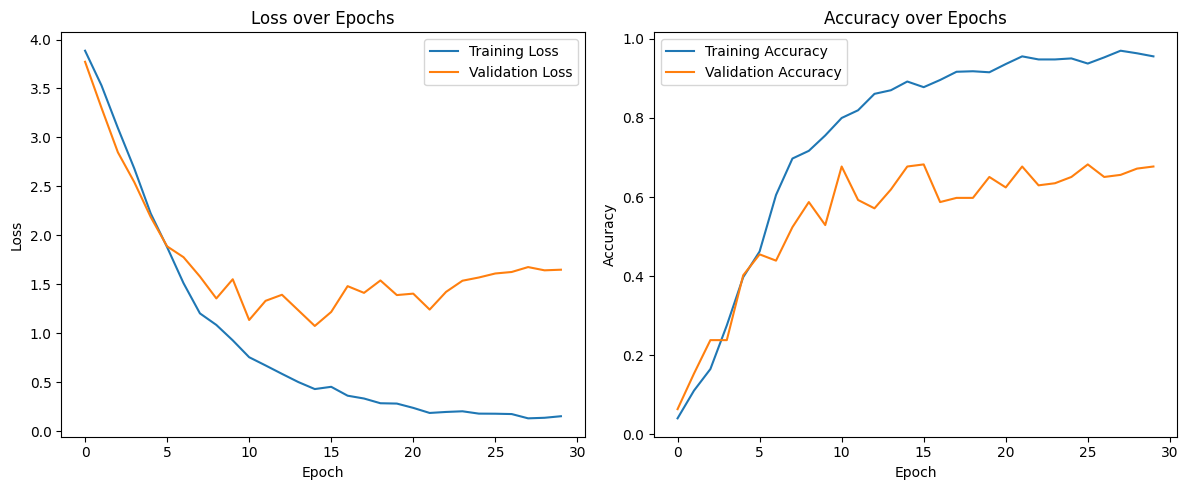

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
version = f"11_fifty_words"
_, best_validation_accuracy, _, _ = evaluate_model(
    model, val_loader, device
)
checkpoint_metadata = {
    "version": version,
    "parameters": parameters,
    "validation_accuracy": best_validation_accuracy,
}

save_gesture_checkpoint(
    f"models/hand_gesture_modelv{version}.pt", model, checkpoint_metadata
)
save_gesture_checkpoint(
    f"website/models/hand_gesture_modelv{version}.pt", model, checkpoint_metadata
)

# Activate v10 only after both checkpoint saves succeed.
with open("website/parameters.json", "w") as destination:
    json.dump(parameters, destination, indent=2)


In [ ]:
# for split_name, gestures in (
#     ("train", train_X),
#     ("validation", val_X),
#     ("test", test_X),
# ):
#     print(
#         f"{split_name}: {len(gestures)} gestures, "
#         f"length {min(map(len, gestures))}-{max(map(len, gestures))} frames"
#     )
# print("The model has no global frame-count contract.")


In [ ]:
deployed_model, checkpoint_metadata = load_gesture_checkpoint(
    "models/hand_gesture_modelv11_fifty_words.pt", device
)
test_loss, test_accuracy, predictions, labels = evaluate_model(
    deployed_model, test_loader, device
)

print(f"Checkpoint test accuracy: {test_accuracy:.3%}")
print(
    classification_report(
        labels,
        predictions,
        target_names=[word_to_number[i] for i in range(len(word_to_number))],
        zero_division=0,
    )
)
print(confusion_matrix(labels, predictions))
